In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

In [2]:
# Dataset Access

In [3]:
df = pd.read_csv("creditcard.csv")

print(df.head())
print(df.shape)
print(df["Class"].value_counts())

# Separate normal and fraudulent transactions
normal_data = df[df["Class"] == 0]
fraud_data = df[df["Class"] == 1]

print("Normal transactions:", len(normal_data))
print("Fraudulent transactions:", len(fraud_data))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
# Data Preprocessing

In [5]:
# Remove class label from input features
X_normal = normal_data.drop("Class", axis=1)
X_fraud = fraud_data.drop("Class", axis=1)

# Normalize features
scaler = StandardScaler()

X_normal_scaled = scaler.fit_transform(X_normal)
X_fraud_scaled = scaler.transform(X_fraud)

# Split normal data into training and validation
X_train, X_val = train_test_split(
    X_normal_scaled,
    test_size=0.2,
    random_state=42
)

# Prepare testing data: normal + fraudulent
X_test = np.vstack((X_val, X_fraud_scaled))

# Actual labels: 0 = Normal, 1 = Fraud
y_test = np.concatenate((
    np.zeros(len(X_val)),
    np.ones(len(X_fraud_scaled))
))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (222477, 30)
Testing shape: (56107, 30)


In [6]:
# Encoder Implementation

In [7]:
input_dim = X_train.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(64, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)

latent = Dense(16, activation="relu")(encoded)

In [8]:
# Decoder Implementation

In [9]:
decoded = Dense(32, activation="relu")(latent)
decoded = Dense(64, activation="relu")(decoded)

output_layer = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(input_layer, output_layer)

In [10]:
# Model Compilation

In [11]:
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 30)            │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 64)            │        1,984 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_1 (Dense)               │ (None, 32)            │        2,080 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_2 (Dense)               │ (None, 16)            │          528 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_3 (Dense)               │ (None, 32)            │          544 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_4 (Dense)               │ (None, 64)            │        2,112 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense_5 (Dense)               │ (None, 30)            │        1,950 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 9,198 (35.93 KB)

 Trainable params: 9,198 (35.93 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Model Training

In [13]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=256,
    validation_data=(X_val, X_val),
    verbose=1
)

Epoch 1/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.3855 - mae: 0.4117 - val_loss: 0.1769 - val_mae: 0.2859
Epoch 2/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - loss: 0.1276 - mae: 0.2298 - val_loss: 0.1095 - val_mae: 0.2098
Epoch 3/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0927 - mae: 0.1878 - val_loss: 0.0852 - val_mae: 0.1836
Epoch 4/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0771 - mae: 0.1665 - val_loss: 0.0881 - val_mae: 0.1882
Epoch 5/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0672 - mae: 0.1513 - val_loss: 0.0633 - val_mae: 0.1483
Epoch 6/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0597 - mae: 0.1400 - val_loss: 0.0593 - val_mae: 0.1470
Epoch 7/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.0524 - mae: 0.1311 - val_loss: 0.0638 - val_mae: 0.1465
Epoch 8/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 0.0471 - mae: 0.1246 - val_loss: 0.0458 - val_mae: 0.1230
Epoch 9/10
870/870 ━━━━━━━━━━━━━━━━━━━━ 1

In [ ]:
# Calculate Reconstruction Error and Threshold

In [14]:
# Reconstruct normal validation data
val_reconstructed = autoencoder.predict(X_val)

# Calculate validation errors
val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=1
)

# Set anomaly threshold
threshold = np.percentile(val_errors, 95)

print("Anomaly Threshold:", threshold)

1739/1739 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step
Anomaly Threshold: 0.16363126100028505


In [15]:
# Anomaly Detection

In [16]:
# Reconstruct test transactions
reconstructed = autoencoder.predict(X_test)

# Calculate reconstruction errors
errors = np.mean(
    np.square(X_test - reconstructed),
    axis=1
)

# Classify transactions
y_pred = (errors > threshold).astype(int)

print("First 10 Reconstruction Errors:")
print(errors[:10])

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\n0 = Normal, 1 = Fraudulent")

1754/1754 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step
First 10 Reconstruction Errors:
[0.00971165 0.02334279 0.4489225  0.00327547 0.17370287 0.12581437
 0.00529285 0.00310784 0.00318784 0.01631128]

First 10 Predictions:
[0 0 1 0 1 0 0 0 0 0]

0 = Normal, 1 = Fraudulent


In [17]:
# Model Evaluation

In [18]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fraud"]
))

Confusion Matrix:
[[52839  2781]
 [   73   414]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97     55620
       Fraud       0.13      0.85      0.22       487

    accuracy                           0.95     56107
   macro avg       0.56      0.90      0.60     56107
weighted avg       0.99      0.95      0.97     56107



In [19]:
# Display Graphs
# Graph 1: Training and Validation Loss

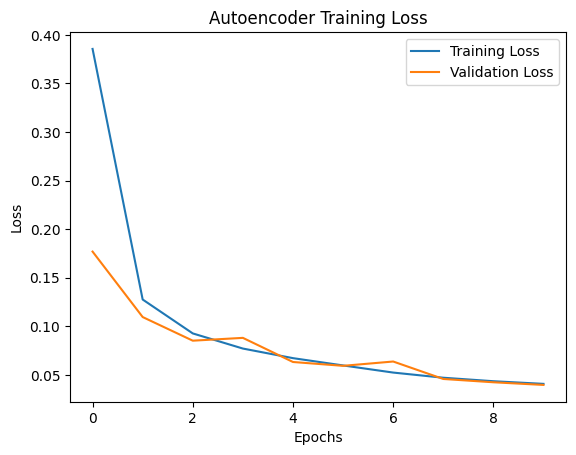

In [20]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")

plt.legend()
plt.show()

In [21]:
# Graph 2: Reconstruction Error and Threshold

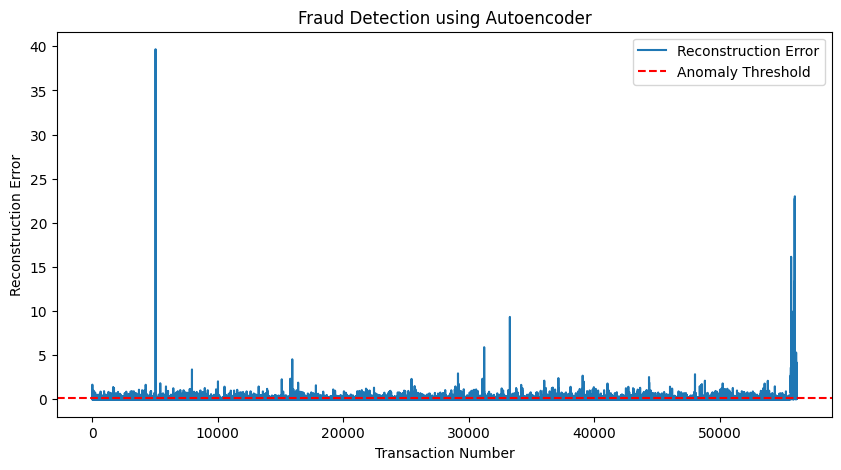

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(errors, label="Reconstruction Error")
plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Transaction Number")
plt.ylabel("Reconstruction Error")
plt.title("Fraud Detection using Autoencoder")

plt.legend()
plt.show()

Here are **25 expected viva questions with answers for Practical 34 – Credit Card Fraud Detection using Autoencoder**.

I've focused on questions an external examiner might ask about your actual code, dataset, Autoencoder architecture and anomaly detection.

# Practical 34 – Credit Card Fraud Detection using Autoencoder

## A. Basic Concepts

**Q1. What is the aim of this practical?**

To identify potentially fraudulent credit card transactions using an Autoencoder-based anomaly detection model.

**Q2. What is an Autoencoder?**

An Autoencoder is an unsupervised neural network that learns to compress input data and reconstruct the original data.

**Q3. What is anomaly detection?**

Anomaly detection is the process of identifying unusual patterns or records that differ from normal behaviour.

**Q4. What dataset is used in this practical?**

Credit Card Fraud Detection dataset. It contains normal and fraudulent credit card transactions.

**Q5. What does the Class column represent?**

It represents whether a transaction is normal or fraudulent:
- 0 = Normal transaction.
- 1 = Fraudulent transaction.

## B. Dataset and Preprocessing

**Q6. Why do we use Pandas?**

To load and manipulate the credit card dataset.

**Q7. How do you load the CSV dataset?**

```python
df = pd.read_csv("creditcard.csv")
```

**Q8. Why do we separate normal and fraudulent transactions?**

Because the Autoencoder is trained only on normal transactions and then tested on both normal and fraudulent transactions.

**Q9. Why do we remove the Class column from input features?**

Because Class is the actual output label. We don't want the model to use the answer while reconstructing transaction features.

**Q10. What is StandardScaler?**

StandardScaler is a preprocessing technique that standardizes data to have approximately zero mean and unit variance.

```python
scaler = StandardScaler()
```

**Q11. Why do we normalize transaction features?**

To bring features to comparable scales so that large numerical values don't dominate the model's learning.

## C. Autoencoder Architecture

**Q12. What are the two main components of an Autoencoder?**

1. Encoder
2. Decoder

**Q13. What is an Encoder?**

The encoder compresses input data into a smaller representation.

**Q14. What is a Decoder?**

The decoder reconstructs the original input from the compressed representation.

**Q15. What is Latent Space?**

Latent space is the compressed representation of input data generated by the encoder.

**Q16. What is the purpose of Dense layers?**

Dense layers are fully connected layers used to learn patterns and relationships in the data.

**Q17. Why do we use ReLU activation?**

ReLU introduces non-linearity and helps the network learn complex patterns.

**Q18. Why do we use Adam optimizer?**

Adam updates the model's weights to minimize the loss function efficiently.

## D. Training and Anomaly Detection

**Q19. Why do we train the Autoencoder only on normal transactions?**

So that it learns normal transaction patterns. Fraudulent transactions may produce higher reconstruction errors.

**Q20. What is MSE?**

MSE stands for Mean Squared Error. It measures the average squared difference between actual and reconstructed values.

**Q21. What is Reconstruction Error?**

It is the difference between the original transaction and its reconstructed output.

**Q22. What is an Anomaly Threshold?**

It is a selected error value used to distinguish normal and fraudulent transactions.

**Q23. How do you classify a transaction as fraudulent?**

If reconstruction error is greater than the threshold, the transaction is classified as fraudulent.

```python
y_pred = (errors > threshold).astype(int)
```

- 0 = Normal
- 1 = Fraudulent

## E. Model Evaluation

**Q24. What is a Confusion Matrix?**

A confusion matrix is used to evaluate classification performance by comparing actual and predicted labels.

It contains:

- True Positive (TP): Fraud correctly identified as fraud.
- True Negative (TN): Normal correctly identified as normal.
- False Positive (FP): Normal incorrectly identified as fraud.
- False Negative (FN): Fraud incorrectly identified as normal.

**Q25. What is Precision and Recall?**

- **Precision:** Out of all transactions predicted as fraudulent, how many were actually fraudulent?
- **Recall:** Out of all actual fraudulent transactions, how many did the model correctly identify?

---

# Important Code-Based Viva Questions

Remember these code statements:

| Code | Purpose |
|---|---|
| `pd.read_csv()` | Loads CSV dataset |
| `df["Class"]` | Accesses class labels |
| `df[df["Class"] == 0]` | Selects normal transactions |
| `df[df["Class"] == 1]` | Selects fraudulent transactions |
| `drop("Class", axis=1)` | Removes class column |
| `StandardScaler()` | Standardizes features |
| `train_test_split()` | Splits data |
| `Input(shape=(input_dim,))` | Defines input layer |
| `Dense(64, activation="relu")` | Creates Dense layer |
| `Dense(16, activation="relu")` | Creates compressed latent representation |
| `Model()` | Creates Autoencoder model |
| `Adam()` | Optimizer |
| `loss="mse"` | Reconstruction loss |
| `model.fit()` | Trains the model |
| `model.predict()` | Reconstructs transactions |
| `np.mean()` | Calculates average error |
| `np.percentile()` | Calculates threshold |
| `confusion_matrix()` | Evaluates predictions |

---

# 5 Most Important Questions – Don't Forget!

If you have limited time, prepare these first:

1. **Why train only on normal transactions?**  
   To learn normal transaction patterns and identify unusual transactions.

2. **What is an Autoencoder?**  
   A neural network that compresses and reconstructs input data.

3. **What is Reconstruction Error?**  
   The difference between original and reconstructed data.

4. **What is a Threshold?**  
   A boundary used to classify normal and abnormal transactions.

5. **What is the difference between Precision and Recall?**  
   Precision measures how many predicted fraud cases are actually fraud; Recall measures how many actual fraud cases are detected.

### One important point for your external exam

Credit card fraud datasets are highly imbalanced: normal transactions are much more numerous than fraudulent transactions.

Therefore, **accuracy alone is not enough** to evaluate fraud detection. Precision, Recall and F1-score are also important.

**Next, I recommend preparing Practical 32 (ECG) and Practical 33 (Energy Consumption), because all three use the same Autoencoder concepts.**